
# California House Prices Exploratory Data Analysis (EDA)

In this notebook, we will perform an in-depth exploratory data analysis on the California Housing dataset.
The main objectives are:
- To understand key features that influence house prices in California.
- To uncover any correlations or trends within the dataset.

By the end of this analysis, we should be able to make some preliminary conclusions about factors that affect 
house prices and be better equipped to build predictive models in future steps.


In [ ]:
!pip install seaborn

In [1]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset from CSV file (assuming the dataset is available in the same directory)
housing_df = pd.read_csv('housing.csv')

# Display the first few rows of the dataset
print(housing_df.head())

# Display dataset info
print(housing_df.info())
    

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0          NaN           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0             NaN   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0         NaN         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0             NaN  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639


## Descriptive Statistics and Data Cleaning

Let's calculate the descriptive statistics of the dataset and check for any missing values.


In [2]:

# Let's generate some descriptive statistics to understand data spread and central tendency.
# This includes mean, median, min, max values, and other key summary statistics.

print(housing_df.describe())


          longitude      latitude  housing_median_age   total_rooms  \
count  20633.000000  20634.000000        20636.000000  20628.000000   
mean    -119.569149     35.631210           28.639659   2636.170109   
std        2.003378      2.135747           12.586419   2182.102273   
min     -124.350000     32.540000            1.000000      2.000000   
25%     -121.800000     33.930000           18.000000   1447.750000   
50%     -118.490000     34.260000           29.000000   2127.000000   
75%     -118.010000     37.710000           37.000000   3148.000000   
max     -114.310000     41.950000           52.000000  39320.000000   

       total_bedrooms    population    households  median_income  \
count    20429.000000  20631.000000  20634.000000   20631.000000   
mean       537.912624   1425.607048    499.571048       3.871563   
std        421.415387   1132.581078    382.334140       1.899751   
min          1.000000      3.000000      1.000000       0.499900   
25%        296.00000

## check for missing values

In [3]:
# Check for missing values
missing_values = housing_df.isnull().sum()
print("Missing values in each column:\n", missing_values[missing_values > 0])

Missing values in each column:
 longitude               7
latitude                6
housing_median_age      4
total_rooms            12
total_bedrooms        211
population              9
households              6
median_income           9
median_house_value      7
ocean_proximity        11
dtype: int64


# Handle Missing Values Using Three Different Methods

### Method 1: Remove Rows with Missing Values
This is useful if the dataset is large and a few missing values won’t impact the analysis significantly.

In [4]:
# Drop rows with any missing values
print("Shape before dropping rows with missing values:", housing_df.shape)
housing_df_dropped = housing_df.dropna()
print("Shape after dropping rows with missing values:", housing_df_dropped.shape)

Shape before dropping rows with missing values: (20640, 10)
Shape after dropping rows with missing values: (20377, 10)


### Method 2: Impute with Mean/Median (for Numerical Columns)
You can replace missing values with the mean (for normally distributed data) or median (for skewed data) of the column.

In [6]:
# Fill missing values with the mean for numerical columns
housing_df_mean_imputed = housing_df.copy()
housing_df_mean_imputed["total_bedrooms"] = housing_df["total_bedrooms"].fillna(housing_df["total_bedrooms"].mean())
missing_values_mean_imputed= housing_df_mean_imputed.isnull().sum()
print("Missing values in each column:\n", missing_values_mean_imputed)

Missing values in each column:
 longitude              7
latitude               6
housing_median_age     4
total_rooms           12
total_bedrooms         0
population             9
households             6
median_income          9
median_house_value     7
ocean_proximity       11
dtype: int64


Or, if you'd prefer to use the median:

In [27]:
housing_df_median_imputed = housing_df_encoded.fillna(housing_df_encoded.median())
housing_df_median_imputed.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,3
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,409.0,8.3014,358500.0,3
2,-122.24,37.85,52.0,2127.0,190.0,496.0,177.0,7.2574,352100.0,3
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,3
4,-122.25,37.85,52.0,1627.0,435.0,565.0,259.0,3.8462,342200.0,3


In [8]:
categorical_cols = housing_df.select_dtypes(include=['object']).columns
print("Categorical columns:", categorical_cols)

Categorical columns: Index(['ocean_proximity'], dtype='object')


### Method 3: Fill for Categorical Columns
For categorical columns, you can replace missing values with the mode (most frequent value).

In [9]:
housing_df_mod_fill = housing_df.copy()
for col in categorical_cols:
    mode_value = housing_df_mod_fill[col].mode()[0]
    housing_df_mod_fill[col].fillna(mode_value, inplace=True)

missing_values_mod_fill= housing_df_mod_fill.isnull().sum()
print("Missing values in each column:\n", missing_values_mod_fill)

Missing values in each column:
 longitude               7
latitude                6
housing_median_age      4
total_rooms            12
total_bedrooms        211
population              9
households              6
median_income           9
median_house_value      7
ocean_proximity         0
dtype: int64


C:\Users\PMYLS\AppData\Local\Temp\ipykernel_22244\1321966915.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  housing_df_mod_fill[col].fillna(mode_value, inplace=True)


#### Forward fill (uses the last known value)
housing_df[categorical_cols] = housing_df[categorical_cols].fillna(method='ffill')

#### Alternatively, backward fill (uses the next known value)
housing_df[categorical_cols] = housing_df[categorical_cols].fillna(method='bfill')

In [14]:
housing_df_ffill =housing_df.copy()
housing_df_ffill[categorical_cols] = housing_df_ffill[categorical_cols].fillna(method='ffill')
missing_values_ffill= housing_df_ffill.isnull().sum()
print("Missing values in categorical column:\n", missing_values_ffill)

Missing values in categorical column:
 longitude               7
latitude                6
housing_median_age      4
total_rooms            12
total_bedrooms        211
population              9
households              6
median_income           9
median_house_value      7
ocean_proximity         0
dtype: int64


C:\Users\PMYLS\AppData\Local\Temp\ipykernel_22244\1130055772.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  housing_df_ffill[categorical_cols] = housing_df_ffill[categorical_cols].fillna(method='ffill')



## Data Visualization

Let's visualize relationships in the dataset using scatter plots, histograms, and box plots.


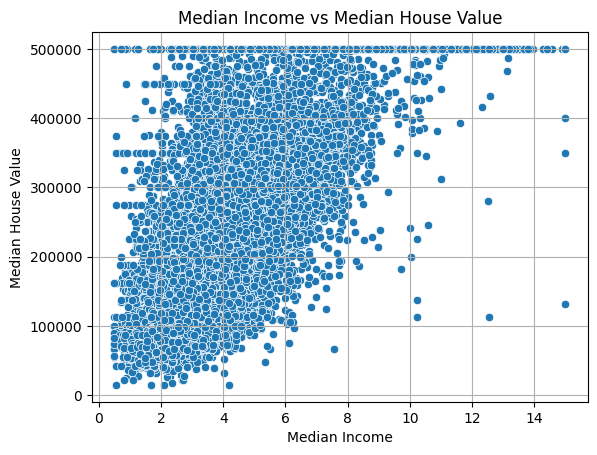

In [15]:

# Scatter plot of Median Income vs Median House Value
sns.scatterplot(x='median_income', y='median_house_value', data=housing_df)
plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.grid(True)
plt.show()


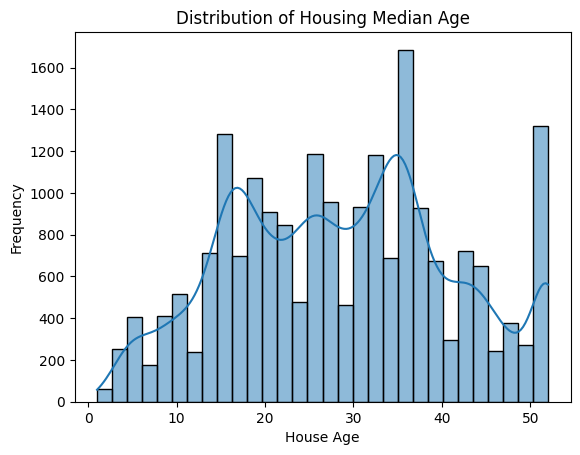

In [16]:

# Histogram for House Age
sns.histplot(housing_df['housing_median_age'], bins=30, kde=True)
plt.title("Distribution of Housing Median Age")
plt.xlabel("House Age")
plt.ylabel("Frequency")
plt.show()


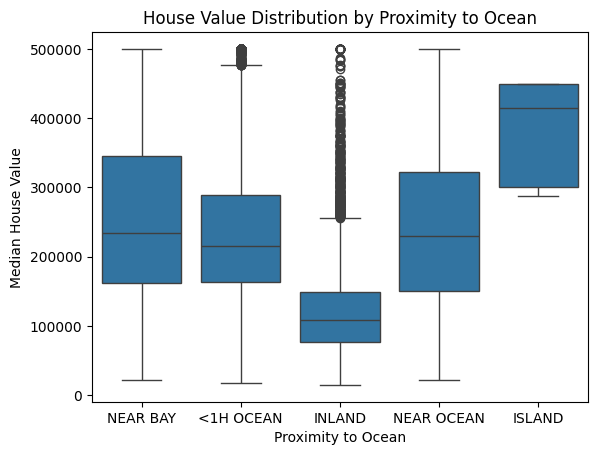

In [17]:

# Box plot of Median House Value by Ocean Proximity
sns.boxplot(x='ocean_proximity', y='median_house_value', data=housing_df)
plt.title("House Value Distribution by Proximity to Ocean")
plt.xlabel("Proximity to Ocean")
plt.ylabel("Median House Value")
plt.show()



## Advanced Visualizations

Let's move on to more advanced visualizations like correlation heatmaps and pair plots.


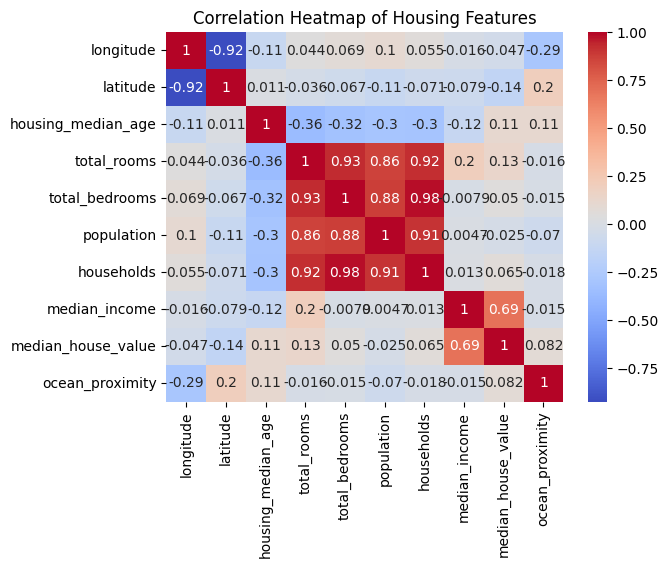

In [ ]:

# Correlation heatmap
corr_matrix = housing_df.corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap of Housing Features")
plt.show()


# Convert Categorical Data to Numeric: 
If you intend to use this data in numeric analysis or modeling, you’ll need to encode the categorical columns. Here’s how:

Label Encoding (useful for ordinal data or quick conversions):

In [21]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
housing_df_encoded=housing_df.copy()
for col in categorical_cols:
    housing_df_encoded[col] = label_encoder.fit_transform(housing_df_encoded[col])
housing_df_encoded.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,3
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,NaN,8.3014,358500.0,3
2,-122.24,37.85,52.0,NaN,190.0,496.0,177.0,7.2574,352100.0,3
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,3
4,-122.25,37.85,52.0,1627.0,NaN,565.0,259.0,3.8462,342200.0,3


# One-Hot Encoding (ideal for non-ordinal categorical data):

In [22]:
housing_df_OHE = pd.get_dummies(housing_df, columns=categorical_cols)
housing_df_OHE.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,False,False,False,True,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,NaN,8.3014,358500.0,False,False,False,True,False
2,-122.24,37.85,52.0,NaN,190.0,496.0,177.0,7.2574,352100.0,False,False,False,True,False
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,False,False,False,True,False
4,-122.25,37.85,52.0,1627.0,NaN,565.0,259.0,3.8462,342200.0,False,False,False,True,False


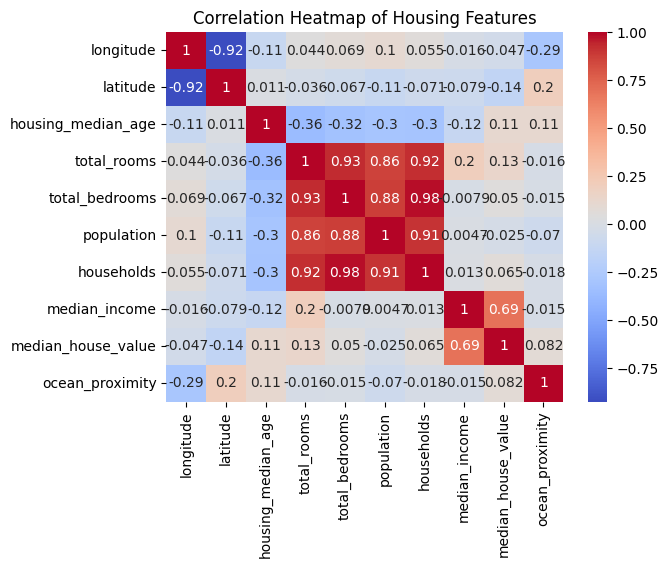

In [23]:

# Correlation heatmap
corr_matrix = housing_df_encoded.corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap of Housing Features")
plt.show()

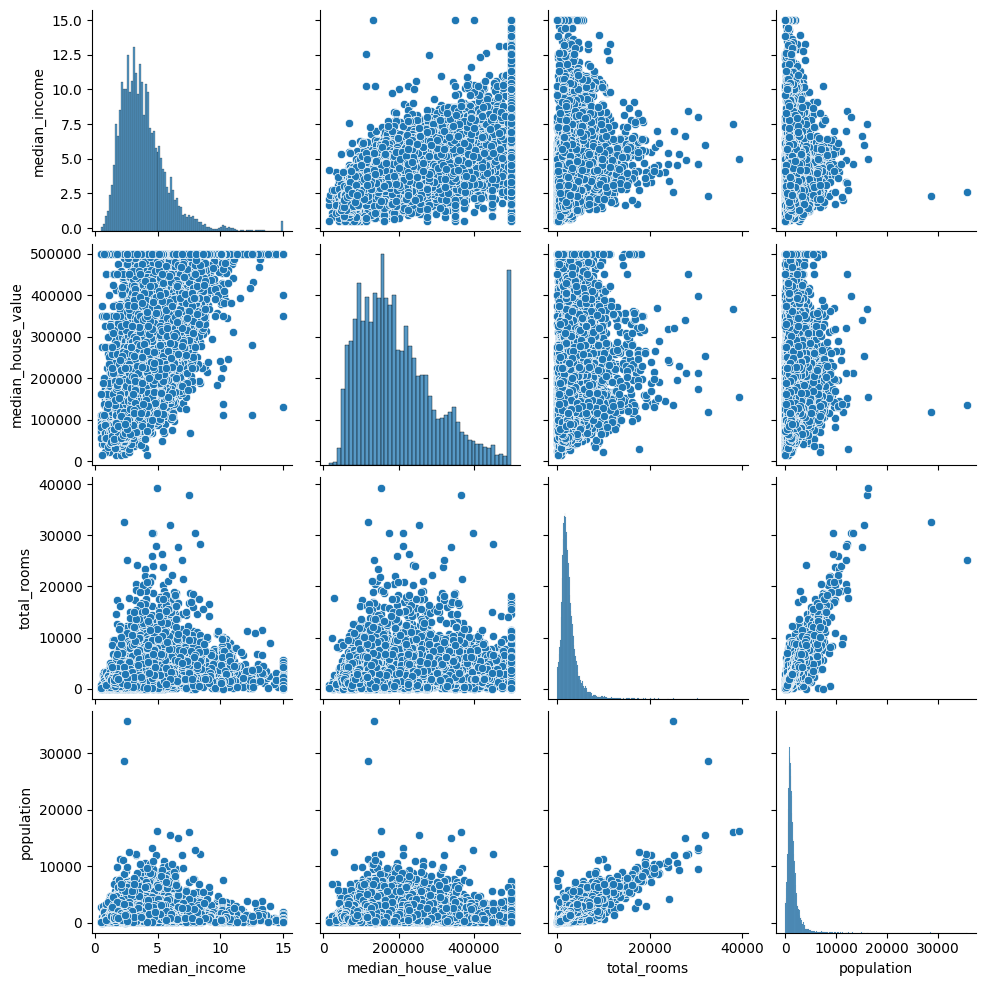

In [24]:

# Pair plot for important features
sns.pairplot(housing_df[['median_income', 'median_house_value', 'total_rooms', 'population']])
plt.show()



## Saving and Reporting

We can save one of the visualizations as an image for reporting purposes.


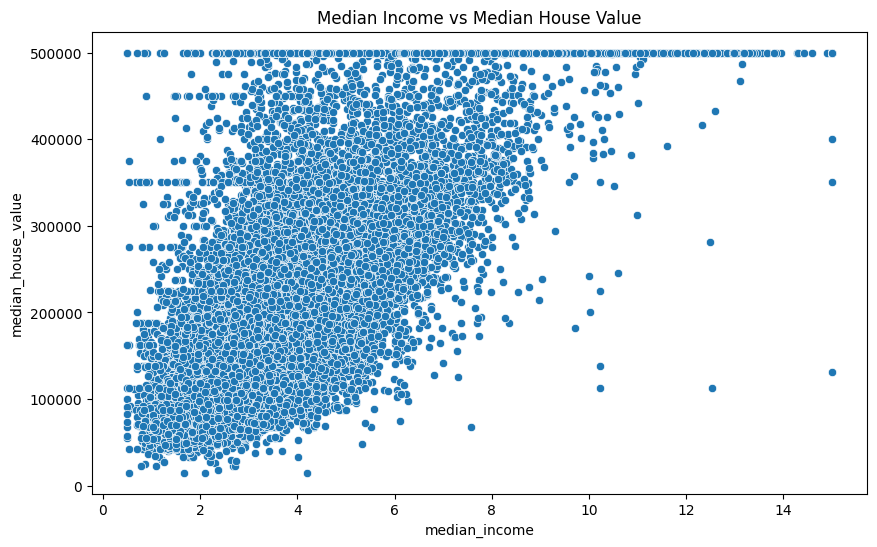

In [25]:

# Save a plot as an image
plt.figure(figsize=(10, 6))
sns.scatterplot(x='median_income', y='median_house_value', data=housing_df)
plt.title("Median Income vs Median House Value")
plt.savefig("income_vs_house_value.png")
plt.show()
